In [ ]:
## Libraries
#Where our conda installation comes into play
# Pandas will be our main go-to libary for data analysis

import pandas as pd
# pandas has something called dataframes

import matplotlib.pyplot as plt
import seaborn as sns

# DATAFRAME 
df = pd.read_csv("U_of_DE_Comp.csv")
print(type(df))
df.head() # first 5 rows
df.info() # summarizes
df.describe() # summary statistics

<class 'pandas.DataFrame'>
<class 'pandas.DataFrame'>
RangeIndex: 300000 entries, 0 to 299999
Data columns (total 46 columns):
 #   Column                       Non-Null Count   Dtype
---  ------                       --------------   -----
 0   Acct1                        300000 non-null  int64
 1   Acct2                        300000 non-null  int64
 2   Acct3                        300000 non-null  int64
 3   Acct4                        300000 non-null  int64
 4   Acct5                        300000 non-null  int64
 5   Acct6                        300000 non-null  int64
 6   Acct7                        300000 non-null  int64
 7   Acct8                        300000 non-null  int64
 8   Acct9                        300000 non-null  int64
 9   Acct10                       300000 non-null  int64
 10  Acct11                       300000 non-null  int64
 11  Acct12                       300000 non-null  str  
 12  Acct13                       300000 non-null  int64
 13  Acct14       

,Acct1,Acct2,Acct3,Acct4,Acct5,Acct6,Acct7,Acct8,Acct9,Acct10,...,line_12m,line_24m,PubRec1,Repo1,Score1,Score2,Util1,Util2,Util3,Util4
count,300000.000000,300000.000000,300000.000000,300000.000000,300000.000000,300000.000000,300000.000000,300000.0,300000.000000,300000.000000,...,300000.000000,300000.000000,300000.0,300000.000000,300000.000000,300000.000000,300000.000000,300000.000000,300000.000000,300000.000000
mean,60.666363,10.751007,8.034900,0.817820,241.567463,5.727093,92.401903,0.0,0.515657,1.685717,...,6435.314937,6679.383707,0.0,0.359747,713.242687,944.603323,88.884500,106.223920,173.063930,26.194657
std,26.599734,26.130304,8.030728,5.844026,589.592883,7.012475,77.586507,0.0,5.839882,6.225303,...,7011.784126,7309.234963,0.0,5.811178,88.895293,1352.023667,180.065914,182.364532,341.861686,33.057367
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,...,0.000000,0.000000,0.0,0.000000,346.000000,357.000000,0.000000,0.000000,0.000000,0.000000
25%,39.000000,1.000000,3.000000,0.000000,114.000000,2.000000,82.000000,0.0,0.000000,0.000000,...,1500.000000,1024.000000,0.0,0.000000,647.000000,662.000000,27.000000,51.000000,6.000000,10.000000
50%,73.000000,3.000000,6.000000,0.000000,194.000000,4.000000,100.000000,0.0,0.000000,0.000000,...,4000.000000,4400.000000,0.0,0.000000,720.000000,733.000000,62.000000,84.000000,28.000000,12.000000
75%,84.000000,5.000000,11.000000,1.000000,289.000000,7.000000,100.000000,0.0,0.000000,2.000000,...,9000.000000,10000.000000,0.0,0.000000,793.000000,799.000000,83.000000,96.000000,86.000000,13.000000
max,99.000000,99.000000,99.000000,99.000000,9999.000000,99.000000,999.000000,0.0,99.000000,99.000000,...,195000.000000,195000.000000,0.0,99.000000,850.000000,9003.000000,999.000000,999.000000,999.000000,99.000000


<Axes: xlabel='bal_12m', ylabel='bad_flg_90plus_24m'>

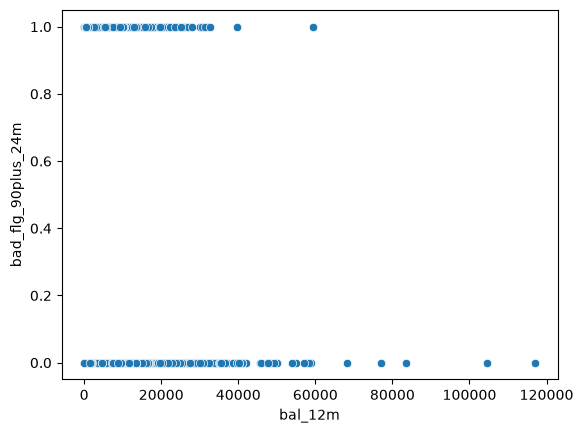

In [ ]:
# Scatter plot for bal_12m vs bad_flg_90plus_24m
sns.scatterplot(x='bal_12m', y='bad_flg_90plus_24m', data=df)

<Axes: xlabel='bal_24m', ylabel='bad_flg_90plus_24m'>

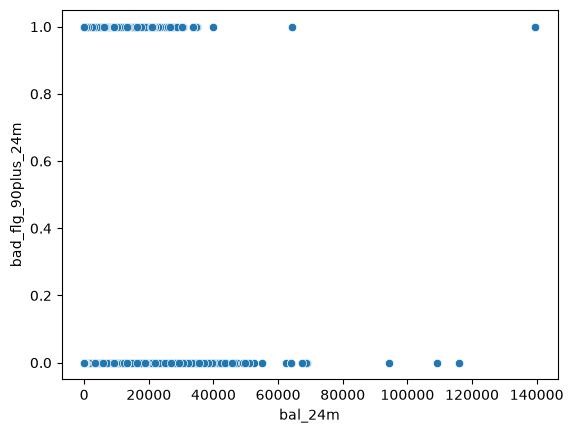

In [ ]:
# Scatterplot for bal_24m vs bad_flg_90plus_24m
sns.scatterplot(x='bal_24m', y='bad_flg_90plus_24m', data=df)

In [24]:
# Histogram
#plt.hist(df['bal_12m'], bins=200)

In [ ]:
# Heatmap
#sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
#plt.show()

In [ ]:
# Linear Regression for bal_12m and bal_24m vs bad_flg_90plus_24m
from sklearn.linear_model import LinearRegression
X = df[['bal_12m', 'bal_24m']]
y = df['bad_flg_90plus_24m']
model = LinearRegression().fit(X, y)
print("R²:", model.score(X, y))

R²: 2.7207068769685705e-05


In [35]:
print(X)

        bal_12m  bal_24m
0             0      794
1         18708    18201
2           775      751
3             0     2215
4             0       47
...         ...      ...
299995        0        0
299996        0        0
299997     1718       27
299998     1625     3407
299999     4661     5722

[300000 rows x 2 columns]


In [37]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# One-Hot Encoding for categorical variables
df_pandas_encoded = pd.get_dummies(df, columns=['Acct12'], drop_first=True)

# Independent variables and target
X = df_pandas_encoded.drop('bad_flg_90plus_24m', axis=1)
y = df_pandas_encoded['bad_flg_90plus_24m']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Fit model
model = LinearRegression()
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

# Evaluation
print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)
print("R² Score:", r2_score(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))


Coefficients: [-1.07681305e-06  2.49740632e-06 -2.85360536e-07  3.78669253e-08
  4.68410751e-06 -2.09711591e-08 -3.06049047e-06 -5.20247636e-17
  5.73986837e-08  3.08313062e-09  1.57334480e-06 -5.43288265e-06
  5.88162425e-10  3.59837957e-09  4.75374514e-06  2.24704574e-06
  9.54514048e-08  6.17999715e-09  2.90443649e-09  4.94668239e-09
  1.12637971e-07  9.92401401e-08 -5.99861512e-11  7.78279822e-08
  8.80425638e-09  1.81913636e-07  1.08464026e-06  1.08678759e-06
  5.71811743e-07  7.23949287e-07 -2.05833470e-06  6.53098185e-08
  7.35118514e-06 -1.11694812e-08  1.11387175e-06 -6.43885166e-06
  0.00000000e+00  6.98256063e-08 -8.03468922e-06 -5.60893149e-06
  4.03525582e-05  4.11470099e-05  5.89226049e-05  4.54011485e-06
 -6.96085779e-10  5.58328651e-14 -5.14273520e-13 -8.18549434e-11
  1.40983705e-09  7.98561937e-11 -9.31320367e-13  1.08111631e-09
  1.57661898e-09]
Intercept: 0.12939915331563595
R² Score: 0.059161536444937046
MSE: 0.05553863534211894
